In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

# Do we think the same thing is happening in all of these countries?

This is a hypothetical dataset representing pesticide residues above a safety threshold vs. percentage of organic farms in different countries. How can we tell if trends are consistent across countries?

x_mean=54.269, y_mean=47.835, linear regression fr(x)=53.8 -0.11 x, r = -0.069 


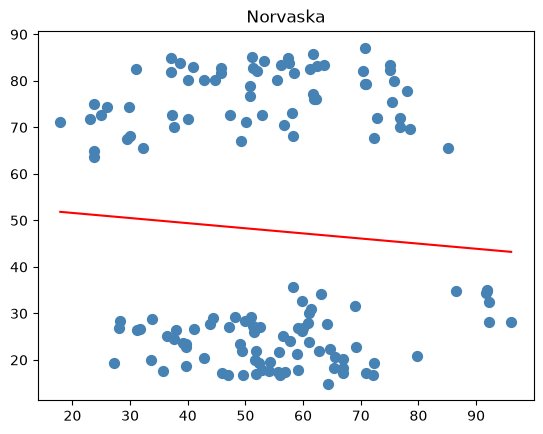

x_mean=54.266, y_mean=47.835, linear regression fr(x)=53.4 -0.10 x, r = -0.064 


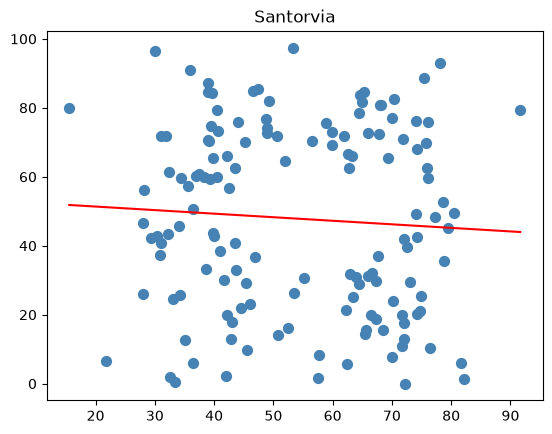

x_mean=54.261, y_mean=47.830, linear regression fr(x)=53.2 -0.10 x, r = -0.062 


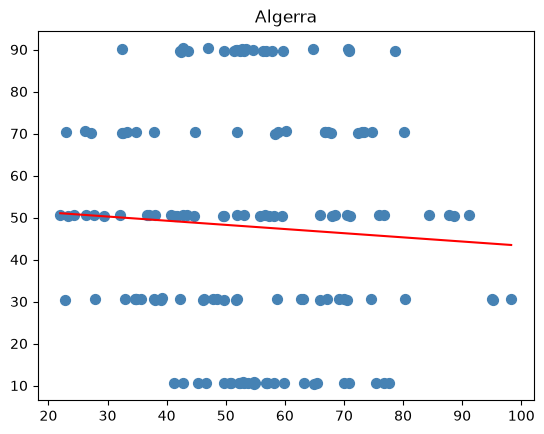

x_mean=54.267, y_mean=47.840, linear regression fr(x)=53.3 -0.10 x, r = -0.063 


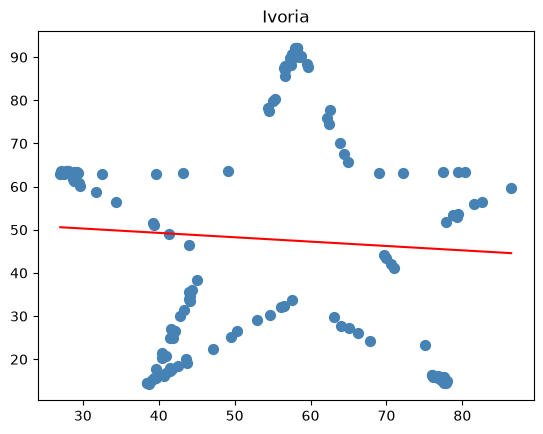

x_mean=54.269, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 


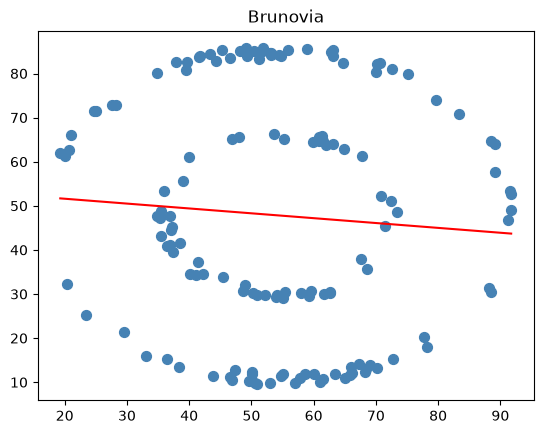

x_mean=54.268, y_mean=47.836, linear regression fr(x)=53.8 -0.11 x, r = -0.069 


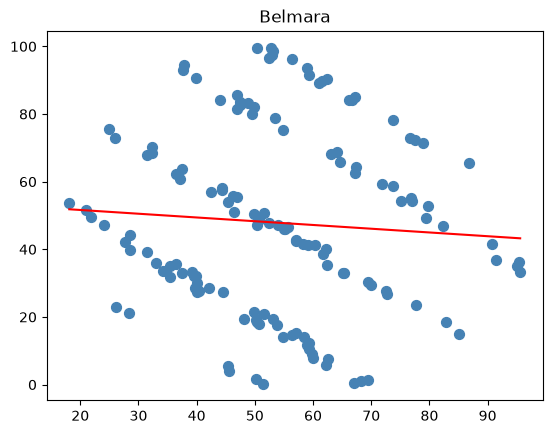

x_mean=54.267, y_mean=47.838, linear regression fr(x)=53.8 -0.11 x, r = -0.068 


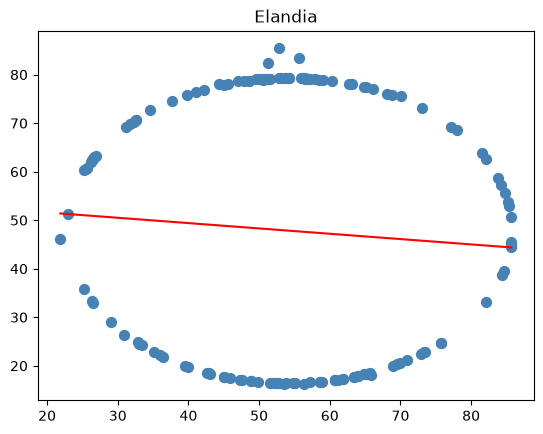

x_mean=54.266, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 


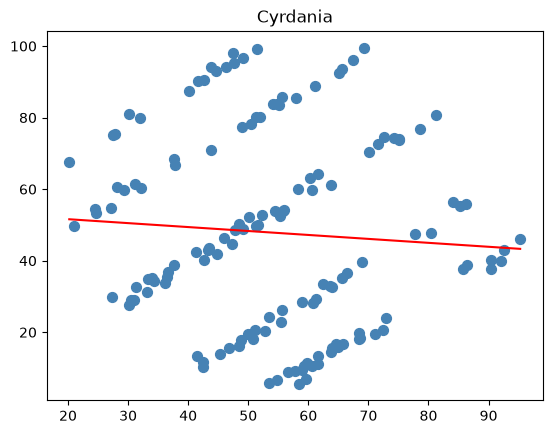

x_mean=54.270, y_mean=47.837, linear regression fr(x)=53.9 -0.11 x, r = -0.069 


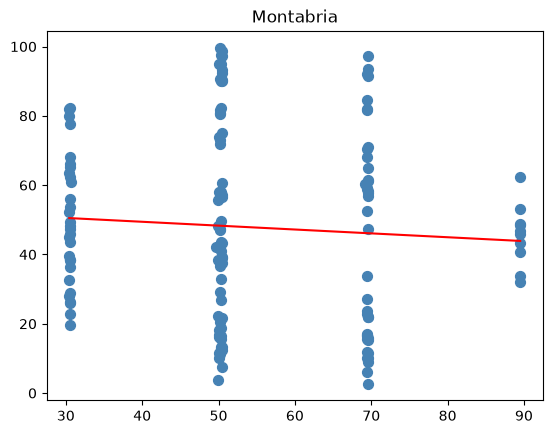

x_mean=54.263, y_mean=47.832, linear regression fr(x)=53.5 -0.10 x, r = -0.064 


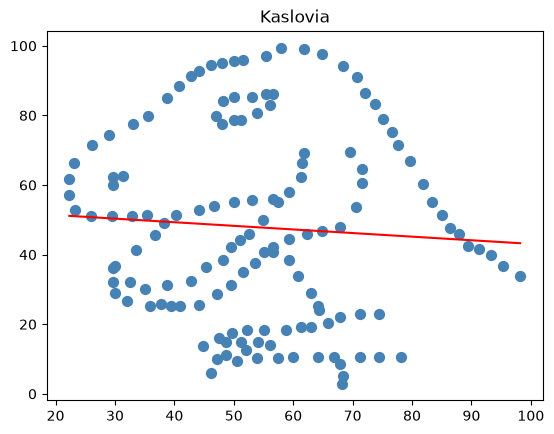

x_mean=54.267, y_mean=47.832, linear regression fr(x)=53.6 -0.11 x, r = -0.067 


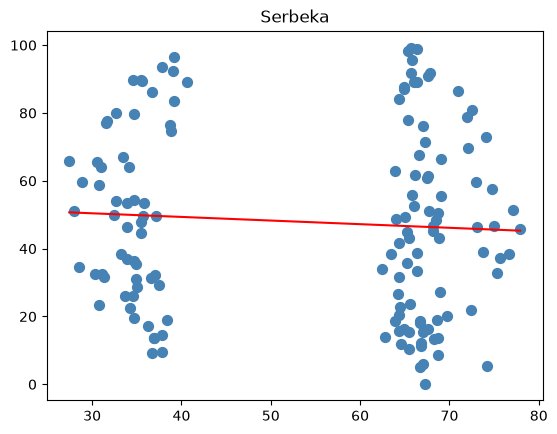

x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.6 -0.11 x, r = -0.066 


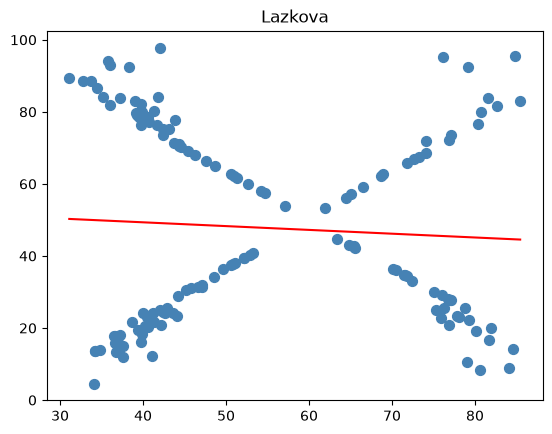

x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.1 -0.10 x, r = -0.060 


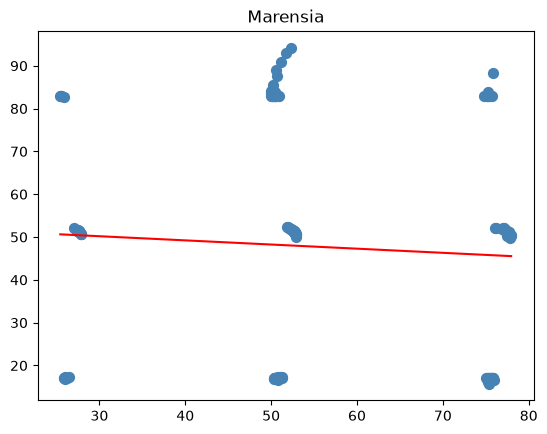

In [8]:
for file in Path('.').glob("*.csv"):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    coeff = np.polyfit(x, y, deg=1)
    corr = np.corrcoef(x, y)[0, 1]
    
    print(f"x_mean={x_mean:.3f}, y_mean={y_mean:.3f}, linear regression fr(x)={coeff[1]:.1f} {coeff[0]:.2f} x, r = {corr:.3f} ")
    xline = np.array([x.min(), x.max()])
    yline = coeff[1] + coeff[0]*xline

    plt.scatter(df["x"], df["y"], color="steelblue", s=50)
    plt.plot(xline, yline, color='red', label='Regressionsgerade')
    plt.title(file.stem)
    # plt.plot(xline, yline, color='red')
    plt.show()


File: Norvaska.csv | x_mean=54.269, y_mean=47.835
File: Santorvia.csv | x_mean=54.266, y_mean=47.835
File: Algerra.csv | x_mean=54.261, y_mean=47.830
File: Ivoria.csv | x_mean=54.267, y_mean=47.840
File: Brunovia.csv | x_mean=54.269, y_mean=47.831
File: Belmara.csv | x_mean=54.268, y_mean=47.836
File: Elandia.csv | x_mean=54.267, y_mean=47.838
File: Cyrdania.csv | x_mean=54.266, y_mean=47.831
File: Montabria.csv | x_mean=54.270, y_mean=47.837
File: Kaslovia.csv | x_mean=54.263, y_mean=47.832
File: Serbeka.csv | x_mean=54.267, y_mean=47.832
File: Lazkova.csv | x_mean=54.260, y_mean=47.840
File: Marensia.csv | x_mean=54.260, y_mean=47.840


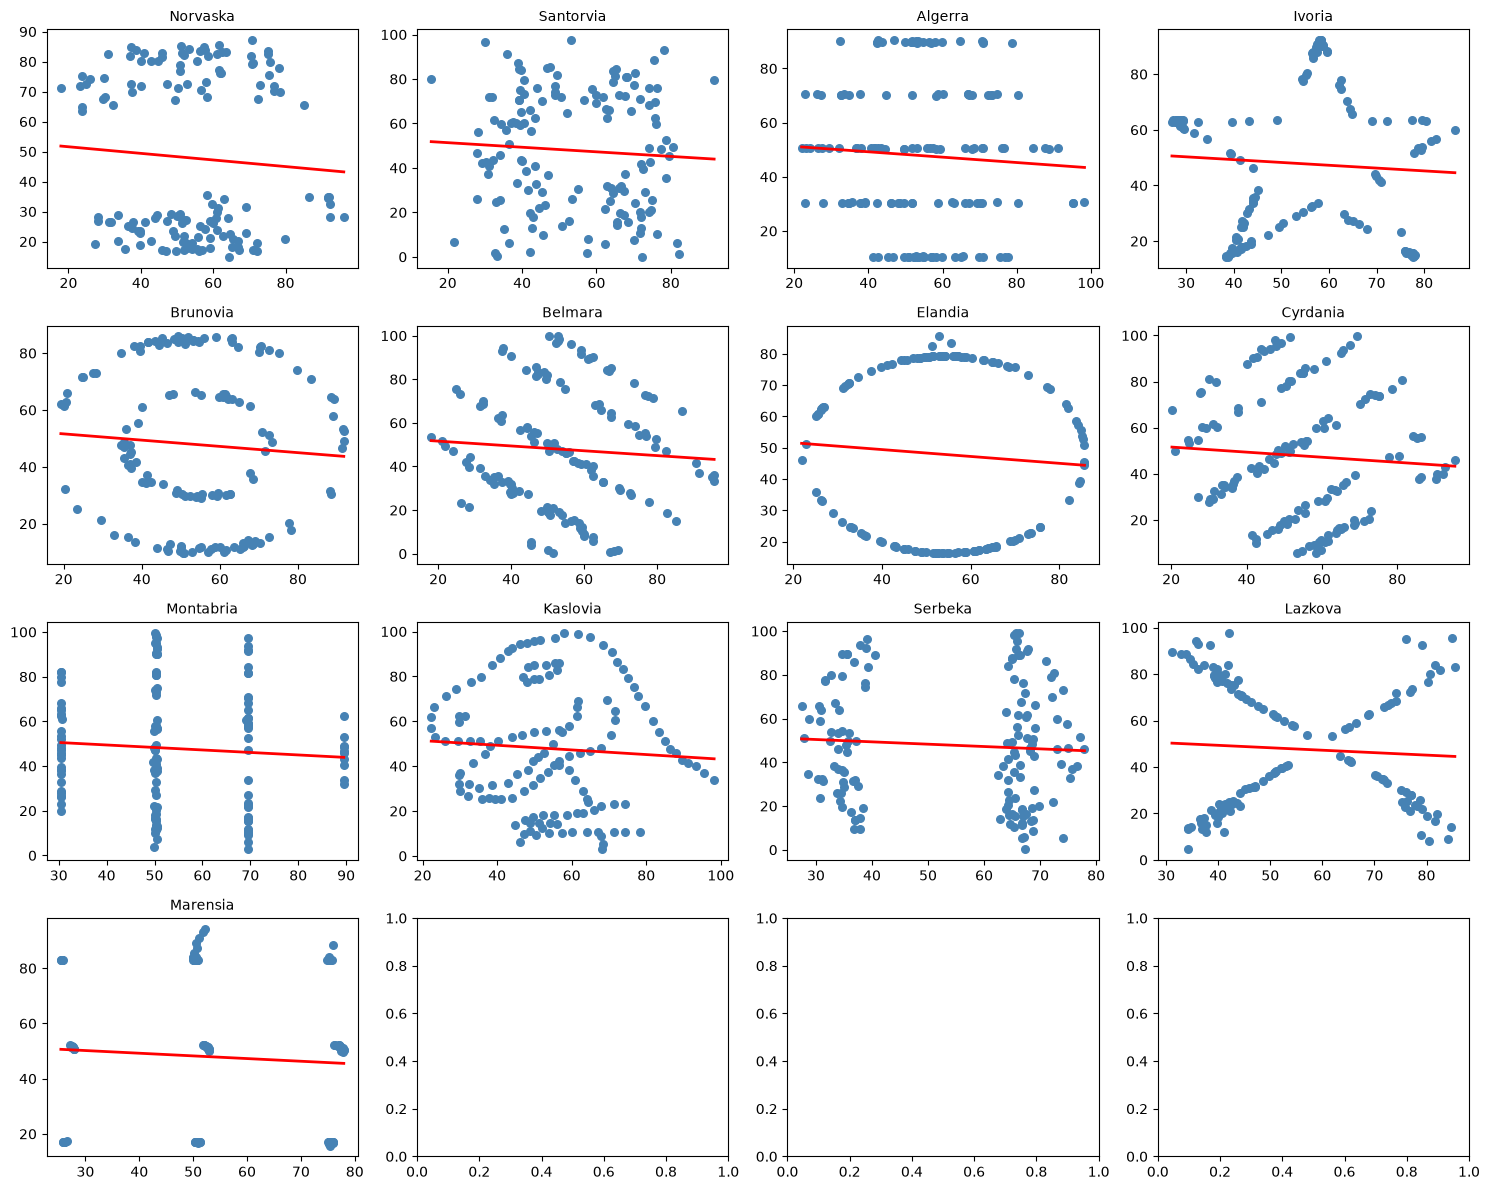

In [7]:
# scatter plot
# plt.scatter(df["x"], df["y"], color="steelblue", s=50)
# plt.show()

# regression line plot
# slope, intercept = np.polyfit(x, y, deg=1)
# plt.plot(x, slope * x + intercept, color='red', label='Regressionsgerade')

# subplots
# fig, axes = plt.subplots(nrows=4, ncols=3, sharex=True, figsize=(6, 12))

# axes[0].plot(df["x"], df["y"]);    axes[0].set_ylabel("Response")
# axes[1].scatter(df["x"], df["y"]); axes[1].set_ylabel("Response")
# axes[2].hist(df["x"], bins=8);     axes[2].set_xlabel("Time (h)"); axes[2].set_ylabel("count")

# plt.tight_layout()
# plt.show()

# 1. Create a grid of subplots (e.g., 3 rows and 4 columns = 12 total plots)
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(15, 12))
axes = axes.flatten()  # Flatten the 2D array of axes into a 1D list for easy looping

# 2. Loop through each file and assign it to an axis in the grid
for i, file in enumerate(Path('.').glob("*.csv")):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    coeff = np.polyfit(x, y, deg=1)
    corr = np.corrcoef(x, y)[0, 1]
    
    print(f"File: {file.name} | x_mean={x_mean:.3f}, y_mean={y_mean:.3f}")
    
    # Calculate regression line coordinates
    xline = np.array([x.min(), x.max()])
    yline = coeff[1] + coeff[0] * xline
    
    # Use axes[i] instead of plt for plotting on the specific subplot
    axes[i].scatter(df["x"], df["y"], color="steelblue", s=30)
    axes[i].plot(xline, yline, color='red', linewidth=2)
    
    # Add titles or labels per subplot
    axes[i].set_title(file.stem, fontsize=10)

# Adjust layout so subplots don't overlap
plt.tight_layout()
plt.show()